In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)



In [3]:
df = pd.read_csv("/kaggle/input/datasets/saurabh00007/iriscsv/Iris.csv")

In [4]:
df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


In [6]:
df = df.iloc[:,1:]

In [8]:
from sklearn.preprocessing import LabelEncoder

In [9]:
encoder = LabelEncoder()

In [10]:
df['Species'] = encoder.fit_transform(df['Species'])

In [13]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [14]:
df = df[df['Species'] != 0][['SepalWidthCm','PetalLengthCm','Species']]

In [15]:
df.head()

,SepalWidthCm,PetalLengthCm,Species
50,3.2,4.7,1
51,3.2,4.5,1
52,3.1,4.9,1
53,2.3,4.0,1
54,2.8,4.6,1


In [16]:
df.shape

(100, 3)

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

<Axes: xlabel='SepalWidthCm', ylabel='PetalLengthCm'>

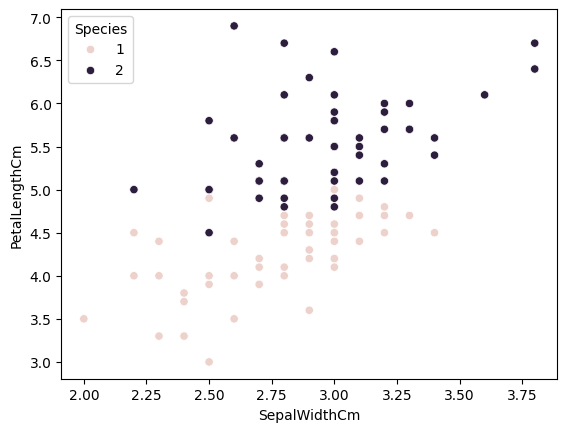

In [18]:
sns.scatterplot(df,x='SepalWidthCm',y='PetalLengthCm',hue='Species')

In [26]:
# Taking only 10 rows for training
df = df.sample(100)
df_train = df.iloc[:60,:].sample(10)
df_val = df.iloc[60:80,:].sample(5)
df_test = df.iloc[80:,:].sample(8)

In [27]:
df_test

,SepalWidthCm,PetalLengthCm,Species
90,2.6,4.4,1
98,2.5,3.0,1
136,3.4,5.6,2
60,2.0,3.5,1
135,3.0,6.1,2
103,2.9,5.6,2
53,2.3,4.0,1
77,3.0,5.0,1


In [28]:
X_test = df_val.iloc[:,0:2].values
y_test = df_val.iloc[:,-1].values

In [29]:
X_test

array([[3. , 4.9],
       [3.2, 5.7],
       [2.5, 5. ],
       [2.8, 4. ],
       [3. , 4.8]])

In [30]:
y_test

array([2, 2, 2, 1, 2])

# Bagging

In [31]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

In [32]:
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]


In [33]:
df_bag

,SepalWidthCm,PetalLengthCm,Species
57,2.4,3.3,1
126,2.8,4.8,2
50,3.2,4.7,1
123,2.7,4.9,2
123,2.7,4.9,2
149,3.0,5.1,2
50,3.2,4.7,1
61,3.0,4.2,1


In [34]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import accuracy_score

In [35]:
dt_bag1 = DecisionTreeClassifier()

In [36]:
def evaluate(clf,X,y):
    clf.fit(X,y)
    plot_tree(clf)
    plt.show()
    plot_decision_regions(X.values, y.values, clf=clf, legend=2)
    y_pred = clf.predict(X_test)
    print(accuracy_score(y_test,y_pred))

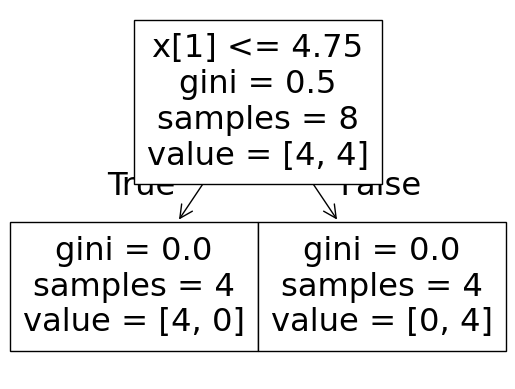

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


1.0


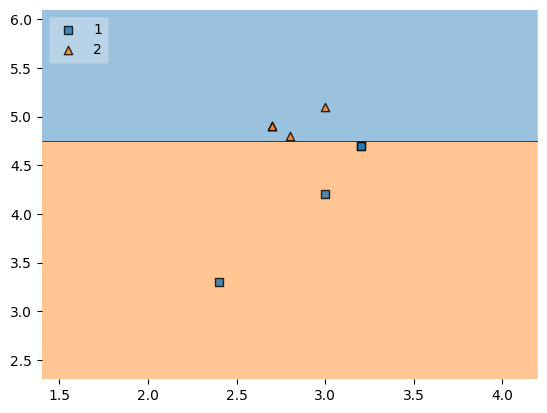

In [37]:
evaluate(dt_bag1,X,y)

In [38]:
# Data for Tree 2
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
126,2.8,4.8,2
149,3.0,5.1,2
139,3.1,5.4,2
57,2.4,3.3,1
61,3.0,4.2,1
50,3.2,4.7,1
114,2.8,5.1,2
114,2.8,5.1,2


In [39]:
dt_bag2 = DecisionTreeClassifier()

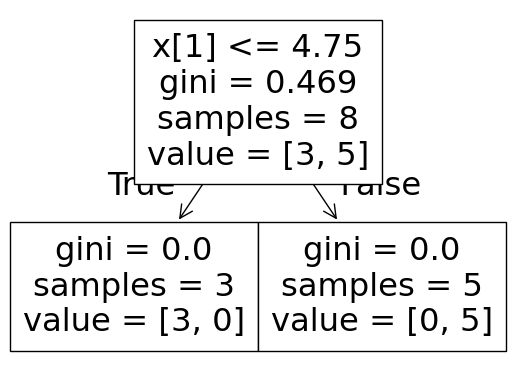

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


1.0


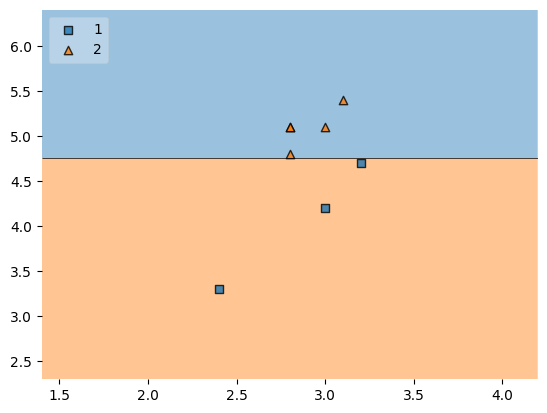

In [40]:
evaluate(dt_bag2,X,y)

In [41]:
# Data for Tree 3
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
114,2.8,5.1,2
149,3.0,5.1,2
123,2.7,4.9,2
123,2.7,4.9,2
121,2.8,4.9,2
139,3.1,5.4,2
121,2.8,4.9,2
57,2.4,3.3,1


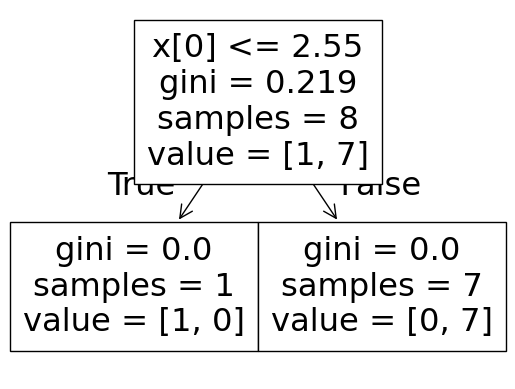

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.6


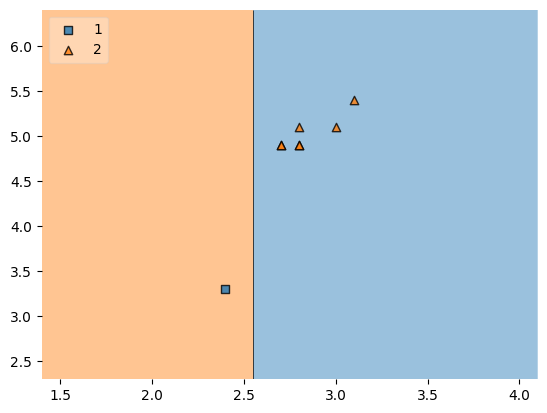

In [43]:
dt_bag3 = DecisionTreeClassifier()
evaluate(dt_bag3,X,y)

# Prediction

In [44]:
df_test

,SepalWidthCm,PetalLengthCm,Species
90,2.6,4.4,1
98,2.5,3.0,1
136,3.4,5.6,2
60,2.0,3.5,1
135,3.0,6.1,2
103,2.9,5.6,2
53,2.3,4.0,1
77,3.0,5.0,1


In [49]:
print("Predictor 1",dt_bag1.predict(np.array([2.0,3.5]).reshape(1,2)))
print("Predictor 2",dt_bag2.predict(np.array([2.0,3.5]).reshape(1,2)))
print("Predictor 3",dt_bag3.predict(np.array([2.0,3.5]).reshape(1,2)))

Predictor 1 [1]
Predictor 2 [1]
Predictor 3 [1]


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


# Pasting

In [50]:
# Row sampling without replacement
df_train

,SepalWidthCm,PetalLengthCm,Species
121,2.8,4.9,2
149,3.0,5.1,2
61,3.0,4.2,1
114,2.8,5.1,2
123,2.7,4.9,2
57,2.4,3.3,1
126,2.8,4.8,2
130,2.8,6.1,2
50,3.2,4.7,1
139,3.1,5.4,2


In [51]:
df_train.sample(8)

,SepalWidthCm,PetalLengthCm,Species
139,3.1,5.4,2
149,3.0,5.1,2
130,2.8,6.1,2
57,2.4,3.3,1
126,2.8,4.8,2
50,3.2,4.7,1
114,2.8,5.1,2
121,2.8,4.9,2


In [65]:
# Data for m1
df_bag = df_train.sample(8)
# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
61,3.0,4.2,1
130,2.8,6.1,2
114,2.8,5.1,2
50,3.2,4.7,1
126,2.8,4.8,2
149,3.0,5.1,2
139,3.1,5.4,2
121,2.8,4.9,2


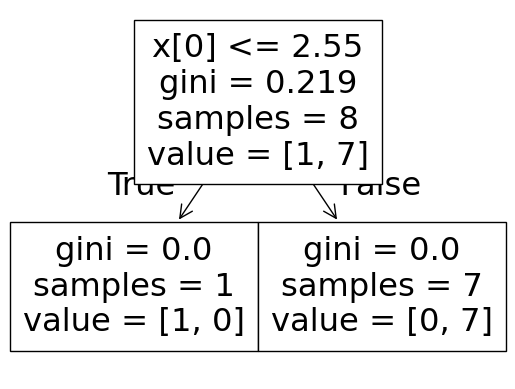

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.6


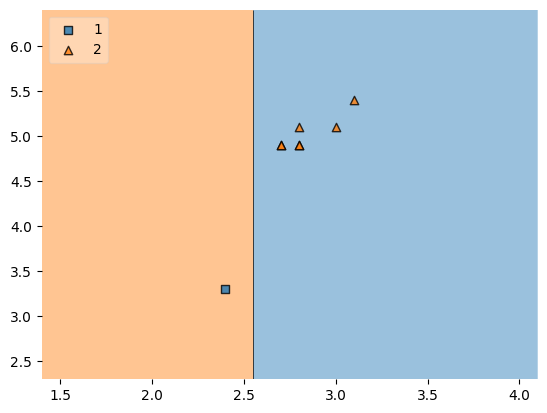

In [53]:
dt_bag1 = DecisionTreeClassifier()
evaluate(dt_bag1,X,y)

In [66]:
# Data for m2
df_bag = df_train.sample(8)
# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
139,3.1,5.4,2
126,2.8,4.8,2
114,2.8,5.1,2
130,2.8,6.1,2
149,3.0,5.1,2
61,3.0,4.2,1
50,3.2,4.7,1
121,2.8,4.9,2


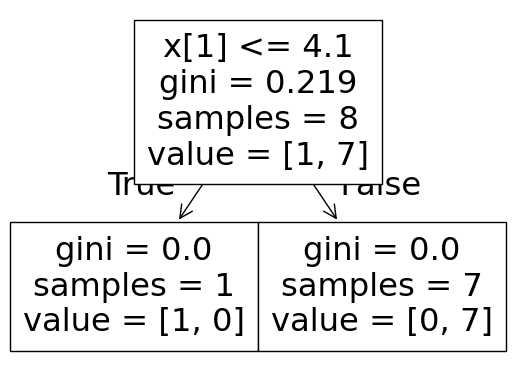

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


1.0


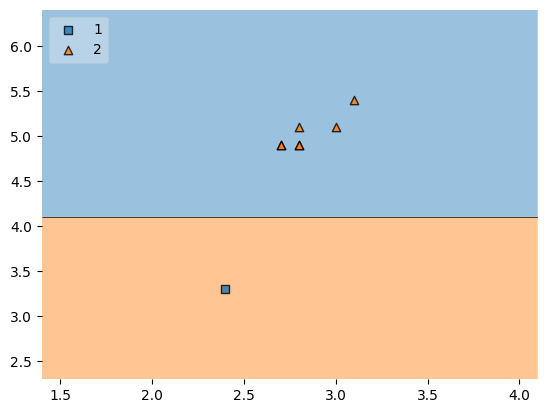

In [63]:
dt_bag2 = DecisionTreeClassifier()
evaluate(dt_bag2,X,y)

In [67]:
# Data for m3
df_bag = df_train.sample(8)
# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
57,2.4,3.3,1
114,2.8,5.1,2
149,3.0,5.1,2
130,2.8,6.1,2
126,2.8,4.8,2
139,3.1,5.4,2
121,2.8,4.9,2
50,3.2,4.7,1


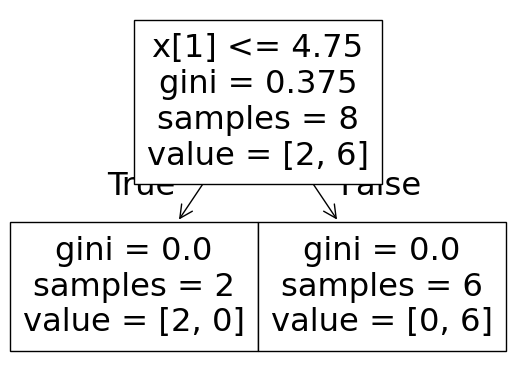

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


1.0


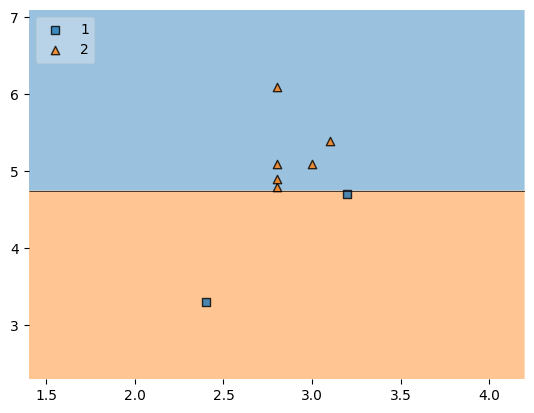

In [68]:
dt_bag3 = DecisionTreeClassifier()
evaluate(dt_bag3,X,y)

In [69]:
df_test

,SepalWidthCm,PetalLengthCm,Species
90,2.6,4.4,1
98,2.5,3.0,1
136,3.4,5.6,2
60,2.0,3.5,1
135,3.0,6.1,2
103,2.9,5.6,2
53,2.3,4.0,1
77,3.0,5.0,1


In [76]:
print("Predictor 1",dt_bag1.predict(np.array([2.9,4.5]).reshape(1,2)))
print("Predictor 2",dt_bag2.predict(np.array([2.9,4.5]).reshape(1,2)))
print("Predictor 3",dt_bag3.predict(np.array([2.9,4.5]).reshape(1,2)))

Predictor 1 [2]
Predictor 2 [2]
Predictor 3 [1]


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


# Random Subspaces
columns wala

In [77]:
df1 = pd.read_csv('/kaggle/input/datasets/saurabh00007/iriscsv/Iris.csv')
df1 = df1.sample(10)

In [78]:
df1

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
89,90,5.5,2.5,4.0,1.3,Iris-versicolor
71,72,6.1,2.8,4.0,1.3,Iris-versicolor
7,8,5.0,3.4,1.5,0.2,Iris-setosa
138,139,6.0,3.0,4.8,1.8,Iris-virginica
16,17,5.4,3.9,1.3,0.4,Iris-setosa
44,45,5.1,3.8,1.9,0.4,Iris-setosa
116,117,6.5,3.0,5.5,1.8,Iris-virginica
88,89,5.6,3.0,4.1,1.3,Iris-versicolor
69,70,5.6,2.5,3.9,1.1,Iris-versicolor


In [80]:
df1.sample(2,replace=True,axis=1)

,PetalWidthCm,Species
0,0.2,Iris-setosa
89,1.3,Iris-versicolor
71,1.3,Iris-versicolor
7,0.2,Iris-setosa
138,1.8,Iris-virginica
16,0.4,Iris-setosa
44,0.4,Iris-setosa
116,1.8,Iris-virginica
88,1.3,Iris-versicolor
69,1.1,Iris-versicolor
